In [3]:
import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt
import tensorflow_datasets as tfds


In [4]:
(ds_train, ds_test), ds_info = tfds.load(
    'malaria',
    split=['train[:80%]', 'train[80%:]'],
    shuffle_files=True,
    as_supervised=True,
    with_info=True
)

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/1 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/malaria/incomplete.PCEVKB_1.0.0/malaria-train.tfrecord*...:   0%|         …

Dataset malaria downloaded and prepared to /root/tensorflow_datasets/malaria/1.0.0. Subsequent calls will reuse this data.


In [7]:
IMG_SIZE = 128
BATCH_SIZE = 32
EPOCHS = 10

class_names = ['Parasitized', 'Uninfected']
num_classes = 2


In [8]:
def preprocess(image, label):
    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))
    image = image / 255.0
    return image, label

In [9]:
train_ds = ds_train.map(preprocess).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
test_ds = ds_test.map(preprocess).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

In [10]:
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
])

In [11]:
model = models.Sequential([

    layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),

    data_augmentation,

    layers.Conv2D(32, (3,3), activation='relu'),
    layers.MaxPooling2D(),

    layers.Conv2D(64, (3,3), activation='relu'),
    layers.MaxPooling2D(),

    layers.Conv2D(128, (3,3), activation='relu'),
    layers.MaxPooling2D(),

    layers.Flatten(),

    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),

    layers.Dense(num_classes, activation='softmax')
])

In [12]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,304,898 (12.61 MB)

 Trainable params: 3,304,898 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

In [13]:
history = model.fit(
    train_ds,
    validation_data=test_ds,
    epochs=EPOCHS
)


Epoch 1/10
689/689 ━━━━━━━━━━━━━━━━━━━━ 29s 33ms/step - accuracy: 0.8588 - loss: 0.3445 - val_accuracy: 0.9503 - val_loss: 0.1744
Epoch 2/10
689/689 ━━━━━━━━━━━━━━━━━━━━ 22s 32ms/step - accuracy: 0.9451 - loss: 0.1746 - val_accuracy: 0.9550 - val_loss: 0.1576
Epoch 3/10
689/689 ━━━━━━━━━━━━━━━━━━━━ 22s 32ms/step - accuracy: 0.9516 - loss: 0.1556 - val_accuracy: 0.9559 - val_loss: 0.1490
Epoch 4/10
689/689 ━━━━━━━━━━━━━━━━━━━━ 21s 30ms/step - accuracy: 0.9546 - loss: 0.1457 - val_accuracy: 0.9556 - val_loss: 0.1434
Epoch 5/10
689/689 ━━━━━━━━━━━━━━━━━━━━ 22s 32ms/step - accuracy: 0.9545 - loss: 0.1440 - val_accuracy: 0.9563 - val_loss: 0.1400
Epoch 6/10
689/689 ━━━━━━━━━━━━━━━━━━━━ 22s 32ms/step - accuracy: 0.9561 - loss: 0.1402 - val_accuracy: 0.9583 - val_loss: 0.1379
Epoch 7/10
689/689 ━━━━━━━━━━━━━━━━━━━━ 21s 31ms/step - accuracy: 0.9573 - loss: 0.1335 - val_accuracy: 0.9572 - val_loss: 0.1373
Epoch 8/10
689/689 ━━━━━━━━━━━━━━━━━━━━ 42s 32ms/step - accuracy: 0.9561 - loss: 0.1318 - 

In [14]:

loss, accuracy = model.evaluate(test_ds)

print("Accuracy:", accuracy)

173/173 ━━━━━━━━━━━━━━━━━━━━ 4s 20ms/step - accuracy: 0.9586 - loss: 0.1284
Accuracy: 0.958635687828064


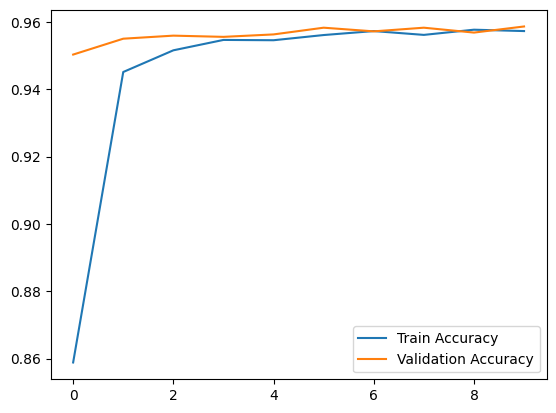

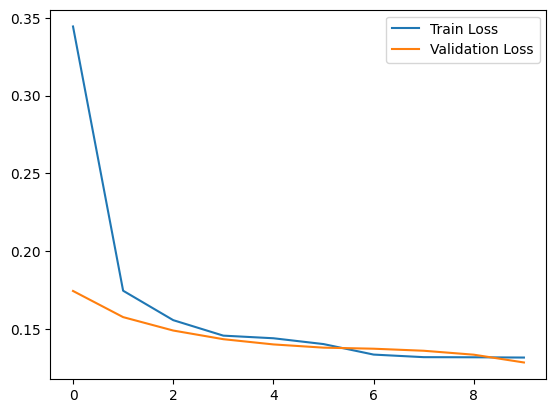

In [15]:
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.legend()
plt.show()

plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.legend()
plt.show()


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 108ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 125ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 134ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 145ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 92ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 167ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 131ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 140ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
1/1 ━

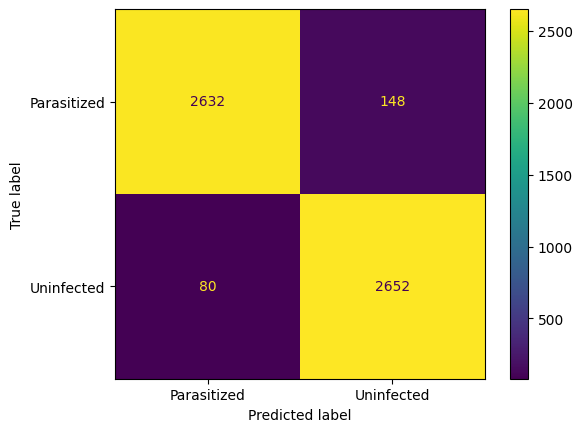

In [41]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import numpy as np

y_true = []
y_pred = []

for images, labels in test_ds:

    predictions = model.predict(images)

    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(predictions, axis=1))

cm = confusion_matrix(y_true, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Parasitized', 'Uninfected']
)

disp.plot()

In [16]:
model.save("malaria_cnn_model.h5")

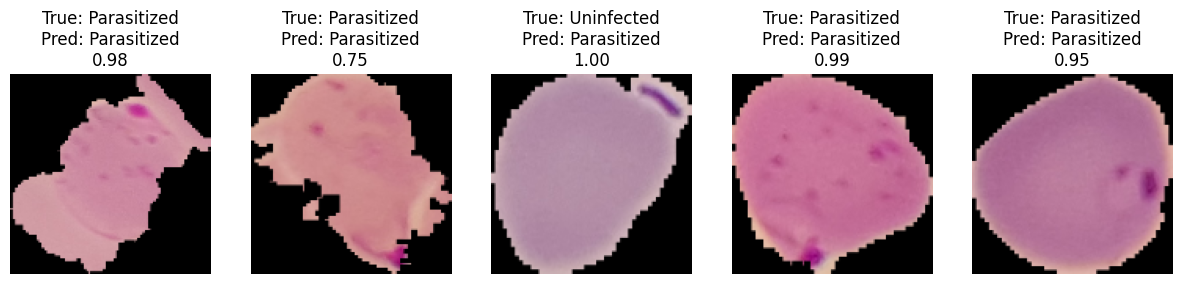

In [27]:
import numpy as np
import matplotlib.pyplot as plt


for images, labels in test_ds.take(1):

    plt.figure(figsize=(15,10))

    for i in range(5):


        plt.subplot(1,5,i+1)
        plt.imshow(images[i])
        plt.axis("off")

        img_array = np.expand_dims(images[i], axis=0)


        prediction = model.predict(img_array, verbose=0)

        class_names = ['Parasitized', 'Uninfected']

        predicted_class = class_names[np.argmax(prediction)]
        true_class = class_names[labels[i].numpy()]

        confidence = np.max(prediction)


        plt.title(
            f"True: {true_class}\nPred: {predicted_class}\n{confidence:.2f}"
        )

    plt.show()

In [28]:
!pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 34.8 MB/s eta 0:00:00


In [31]:
import tensorflow_datasets as tfds
import os
import cv2


(ds_train, ds_val), ds_info = tfds.load(
    'malaria',
    split=['train[:80%]', 'train[80%:]'],
    as_supervised=True,
    with_info=True
)

classes = ['Parasitized', 'Uninfected']

for split in ['train', 'val']:
    for cls in classes:
        os.makedirs(f"malaria_dataset/{split}/{cls}", exist_ok=True)


for i, (image, label) in enumerate(ds_train):
    class_name = classes[label.numpy()]
    img = image.numpy()
    path = f"malaria_dataset/train/{class_name}/{i}.jpg"
    cv2.imwrite(path, cv2.cvtColor(img, cv2.COLOR_RGB2BGR))


for i, (image, label) in enumerate(ds_val):
    class_name = classes[label.numpy()]
    img = image.numpy()
    path = f"malaria_dataset/val/{class_name}/{i}.jpg"
    cv2.imwrite(path, cv2.cvtColor(img, cv2.COLOR_RGB2BGR))

print("Dataset جاهزة لـ YOLO")

Dataset جاهزة لـ YOLO


In [32]:
from ultralytics import YOLO

yolo_model = YOLO("yolo11n-cls.pt")

yolo_results = yolo_model.train(
    data="malaria_dataset",
    epochs=10,
    imgsz=128,
    batch=32
)

Ultralytics 8.4.49 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=malaria_dataset, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=10, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=128, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n-cls.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train-2, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=100, perspec

In [33]:
metrics = yolo_model.val()

print(metrics)

Ultralytics 8.4.49 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n-cls summary (fused): 47 layers, 1,528,586 parameters, 0 gradients, 3.2 GFLOPs
train: /content/malaria_dataset/train... found 22046 images in 2 classes ✅ 
val: /content/malaria_dataset/val... found 5512 images in 2 classes ✅ 
test: None...
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 325.3±150.7 MB/s, size: 8.1 KB)
val: Scanning /content/malaria_dataset/val... 5512 images, 0 corrupt: 100% ━━━━━━━━━━━━ 5512/5512 1.4Git/s 0.0s
               classes   top1_acc   top5_acc: 100% ━━━━━━━━━━━━ 345/345 33.1it/s 10.4s
                   all      0.967          1
Speed: 0.0ms preprocess, 1.1ms inference, 0.0ms loss, 0.0ms postprocess per image
Results saved to /content/runs/classify/val
ultralytics.utils.metrics.ClassifyMetrics object with attributes:

confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7a06ff7d10d0>
curves: []
curves_results: []
fitness: 0.9833998680114746
keys: 

In [34]:
cnn_loss, cnn_accuracy = model.evaluate(test_ds)

print("CNN Accuracy:", cnn_accuracy)
print("CNN Loss:", cnn_loss)

173/173 ━━━━━━━━━━━━━━━━━━━━ 4s 23ms/step - accuracy: 0.9586 - loss: 0.1284
CNN Accuracy: 0.958635687828064
CNN Loss: 0.12840716540813446


In [35]:
yolo_metrics = yolo_model.val()

print("YOLO Top1 Accuracy:", yolo_metrics.top1)
print("YOLO Top5 Accuracy:", yolo_metrics.top5)

Ultralytics 8.4.49 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
train: /content/malaria_dataset/train... found 22046 images in 2 classes ✅ 
val: /content/malaria_dataset/val... found 5512 images in 2 classes ✅ 
test: None...
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 463.9±223.4 MB/s, size: 8.1 KB)
val: Scanning /content/malaria_dataset/val... 5512 images, 0 corrupt: 100% ━━━━━━━━━━━━ 5512/5512 2.3Git/s 0.0s
               classes   top1_acc   top5_acc: 100% ━━━━━━━━━━━━ 345/345 46.3it/s 7.4s
                   all      0.967          1
Speed: 0.0ms preprocess, 0.9ms inference, 0.0ms loss, 0.0ms postprocess per image
Results saved to /content/runs/classify/val-2
YOLO Top1 Accuracy: 0.9667997360229492
YOLO Top5 Accuracy: 1.0


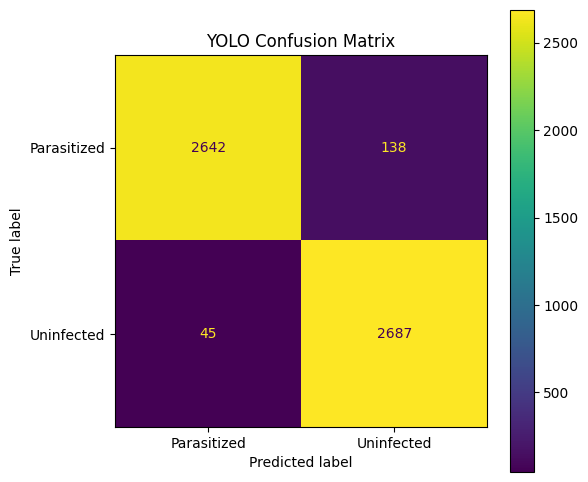

In [44]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import glob
import os

y_true = []
y_pred = []

class_names = ['Parasitized', 'Uninfected']

image_paths = glob.glob("malaria_dataset/val/*/*.jpg")

for img_path in image_paths:

    true_class_name = os.path.basename(os.path.dirname(img_path))
    true_label = class_names.index(true_class_name)
    y_true.append(true_label)


    results = yolo_model(img_path, verbose=False)
    pred_label = results[0].probs.top1
    y_pred.append(pred_label)


cm = confusion_matrix(y_true, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(6,6))
disp.plot(ax=ax)
plt.title("YOLO Confusion Matrix")
plt.show()

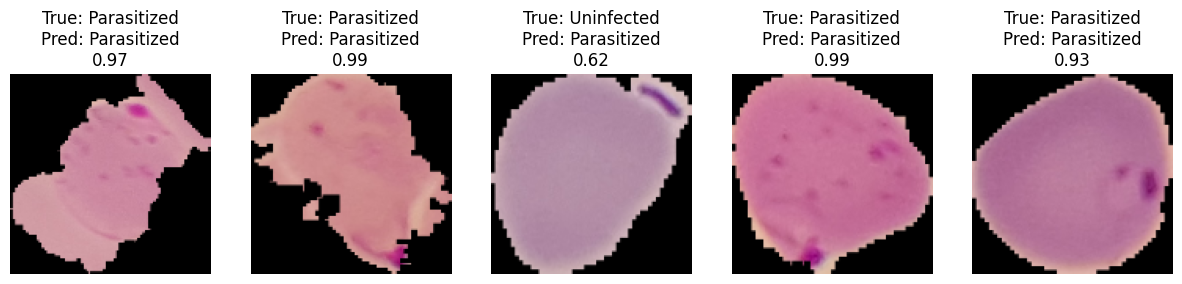

In [51]:
import numpy as np
import matplotlib.pyplot as plt

for images, labels in test_ds.take(1):

    plt.figure(figsize=(15,10))

    for i in range(5):


        plt.subplot(1,5,i+1)
        plt.imshow(images[i])
        plt.axis("off")


        img_array = (images[i].numpy() * 255).astype("uint8")

        results = yolo_model(img_array, verbose=False)

        class_names = ['Parasitized', 'Uninfected']

        predicted_class = class_names[results[0].probs.top1]
        true_class = class_names[labels[i].numpy()]

        confidence = results[0].probs.top1conf


        plt.title(
            f"True: {true_class}\nPred: {predicted_class}\n{confidence:.2f}"
        )

    plt.show()

In [38]:
from sklearn.metrics import classification_report

print(classification_report(
    y_true,
    y_pred,
    target_names=['Parasitized', 'Uninfected']
))

              precision    recall  f1-score   support

 Parasitized       0.97      0.95      0.96      2780
  Uninfected       0.95      0.97      0.96      2732

    accuracy                           0.96      5512
   macro avg       0.96      0.96      0.96      5512
weighted avg       0.96      0.96      0.96      5512



In [ ]:
import matplotlib.pyplot as plt

models = ["CNN", "YOLO"]
accuracies = [95.86, 96.68]

plt.bar(models, accuracies)
plt.title("CNN vs YOLO Validation Accuracy")
plt.xlabel("Model")
plt.ylabel("Accuracy (%)")
plt.ylim(90, 100)
plt.show()
